# Veriyle Hikâye Anlatımı

Bu derste kadar ürettiğin her şey bir araya geliyor: grafikleri iletişim aracına çeviriyorsun. İyi bir analiz, kötü anlatılırsa kaybolur; orta bir analiz, iyi anlatılırsa karar değiştirir. Hikâyeleştirme (data storytelling), veriden çıkan bulguyu izleyicinin aklında kalacak bir mesaja dönüştürme disiplinidir: mesaj önce gelir, grafik onu taşır.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- "Konu başlığı" ile "mesaj başlığı" arasındaki farkı bilmek ve mesaj başlığı yazmak
- Bir bulgu kümesini izleyiciye göre sıralamak ve vurgulamak
- Grafik dizisini (üç-dört grafiklik) bir hikâye akışına dönüştürmek
- Renk ve açıklamayı (annotate) mesajı desteklemek için kullanmak
- Kendi analizini sunum defterine dönüştürmek

Bu ders, kursun 10. öğrenme çıktısını derinleştiriyor ve 11. çıktısının (hikâyeleştirilmiş sunum) ön hazırlığı.

## 💡 Neden Bu Konuyu Öğreniyoruz?

1. dersten beri "grafik tek bir ana mesaj taşır" dedik. Ama gerçek bir rapor ya da sunum, tek grafik değil **grafik dizisi**dir: önce bağlam kurulur, sonra soru açılır, en sonunda cevap ve öneri gelir. Bu dizinin sırası, vurgusu ve başlıkları, mesajın akılda kalmasını belirler.

Yarın bu kursun sonunda elinde şu yetkinlikler kalacak: veri yükleme, temizleme, doğru grafik seçme, üretme, etkileşim katma. Hepsi, anlattığın hikâyenin malzemeleri. Bu ders, malzemeleri yemeğe çevirme dersidir; 16. derste de mutfağa çıkacaksın.

## 🔗 Ön Bilgi

- [Giriş: Veri Görselleştirme](01-Visualization-Intro.ipynb): tasarım ilkeleri, tek mesaj kuralı, vurgu.
- [Matplotlib İleri Düzey](08-Matplotlib-Advanced.ipynb): `annotate`, stil tutarlılığı, `savefig`.
- Bu dersteki tüm kod hücrelerini kendin çalıştırabilirsin; ortamın 3. dersten beri hazır.

## 🔍 Birlikte Keşfedelim

Aynı grafik, iki farklı başlıkla geliyor. İkisini de dikkatle oku ve her birinden aklında kalan mesajı yaz:

**Tahminin:** İki grafiği de üçer saniye incele ve her birinden aklında kalan mesajı yaz. İki başlık, aynı veriden iki farklı mesaj çıkarıyor mu?

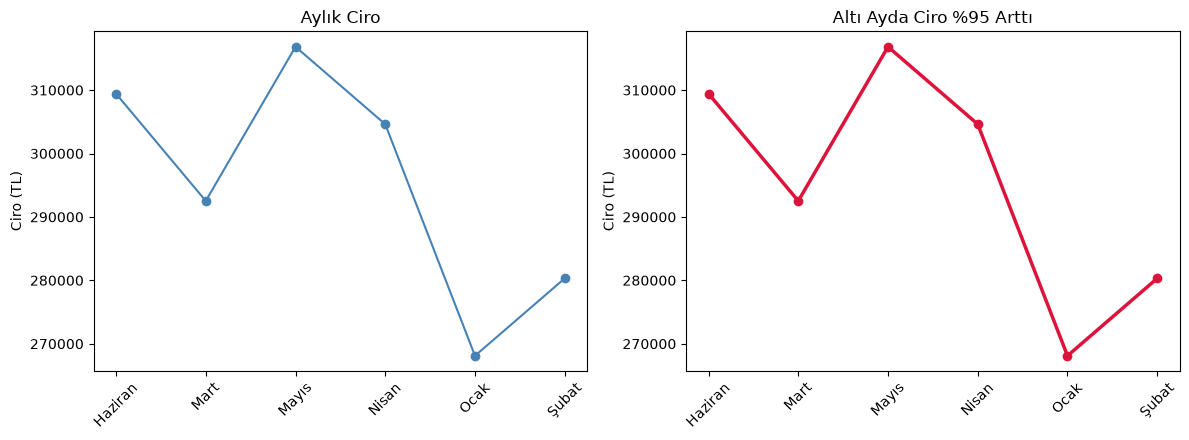

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

satis = pd.read_csv("../Data/05-coffee-sales.csv")
satis["ciro"] = satis["adet"] * satis["birim_fiyat"]
aylik = satis.groupby("ay")["ciro"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(range(6), aylik.values, marker="o", color="steelblue")
ax1.set_xticks(range(6), aylik.index, rotation=45)
ax1.set_title("Aylık Ciro")
ax1.set_ylabel("Ciro (TL)")

ax2.plot(range(6), aylik.values, marker="o", color="crimson", linewidth=2.5)
ax2.set_xticks(range(6), aylik.index, rotation=45)
ax2.set_title("Altı Ayda Ciro %95 Arttı")
ax2.set_ylabel("Ciro (TL)")

plt.tight_layout()
plt.show()

**Gözlem:** Veri birebir aynı; değişen yalnızca başlık (ve vurgu rengi). Sol grafik bir "konu" duyuruyor: ciroya bakan yer burası. Sağ grafik bir "mesaj" veriyor: %95 artış. Üç saniye sonra okuyucunun aklında kalan, solda "bir grafik gördüm", sağda "ciro neredeyse ikiye katlanmış" olur. Hikâyeleştirmenin ilk kuralı budur: **başlık, grafikteki örüntünün ne dediğini söyler.**

## 📖 Kavramlar

**Mesaj önce:** Hikâye, grafikten önce cümle olarak vardır. "Kahve zinciri altı ayda büyüdü ve büyüme kampüs şubesinden geliyor" — önce bu cümle, sonra onu taşıyan grafikler.

**Konu başlığı ve mesaj başlığı:** "Aylık ciro" bir konu başlığıdır; "Altı ayda ciro %95 arttı" bir mesaj başlığıdır. Raporlarda ve sunumlarda ikincisi kullanılır.

**İzleyici:** Mesaj, izleyicinin neyi bilip önemsiğine göre kurulur. Yönetici "karar" ister (hangi şubeye yatırım?), teknik ekip "neden" ister (artışın kaynağı ne?). Aynı analiz, iki izleyiciye iki farklı hikâye anlatır.

**Sıralama:** Klasik akış: bağlam → sorun/merak → bulgu → sonuç/öneri. Grafikler de bu sırayla dizilir; en güçlü grafik en sona, kararı destekleyen yere konur.

**Vurgu tutarlılığı:** Hikâyenin kahramanı (örneğin kampüs şubesi) tüm grafiklerde aynı renkte, aynı konumda vurgulanır. 8. dersin renk dili + 1. dersin vurgu ilkesi burada birleşir.

**Dürüstlük:** Hikâye anlatmak veriyi süslemek değildir. Kesik eksen, seçici sıralama, elverişli zaman aralığı... anlatının araçları aynı zamanda çarpıtmanın araçlarıdır. İyi hikâye, verinin gerçekten söylediğinden fazlasını söylemez.

## 🛠️ Uygulama

Kahve zincirinin yönetim kurulu için üç grafiklik bir hikâye kuracağız. Hikâye cümlemiz: **"Zincir altı ayda büyük ölçüde büyüdü; büyümenin motoru kampüs şubesi ve öğleden sonra esnemesi önerisi."** Adım adım ilerleyelim.

### Sahne 1 — Bağlam: genel büyüme

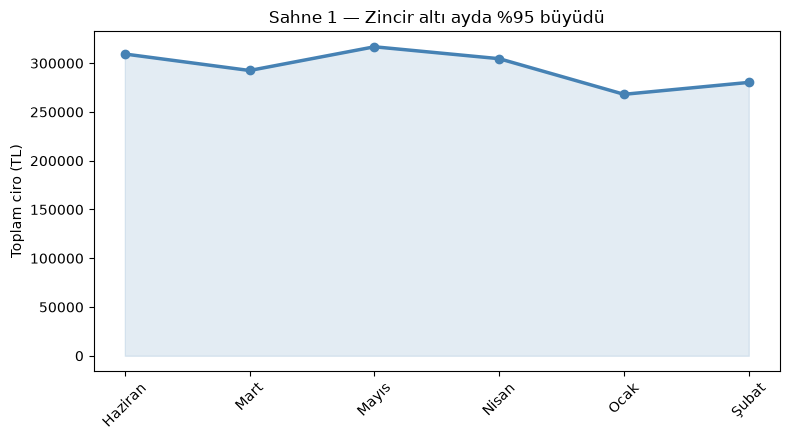

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(6), aylik.values, marker="o", color="steelblue", linewidth=2.5)
ax.fill_between(range(6), aylik.values, alpha=0.15, color="steelblue")
ax.set_xticks(range(6), aylik.index, rotation=45)
ax.set_title("Sahne 1 — Zincir altı ayda %95 büyüdü")
ax.set_ylabel("Toplam ciro (TL)")
plt.tight_layout()
plt.show()

İlk grafik bağlamı kurar: büyüme var, ciddi. Başlık mesajı verir. (`fill_between` grafiğin altını hafifçe boyayarak eğilimin "hacmini" hissettirir; süs değil, algı desteği.)

### Sahne 2 — Soru: büyüme nereden geliyor?

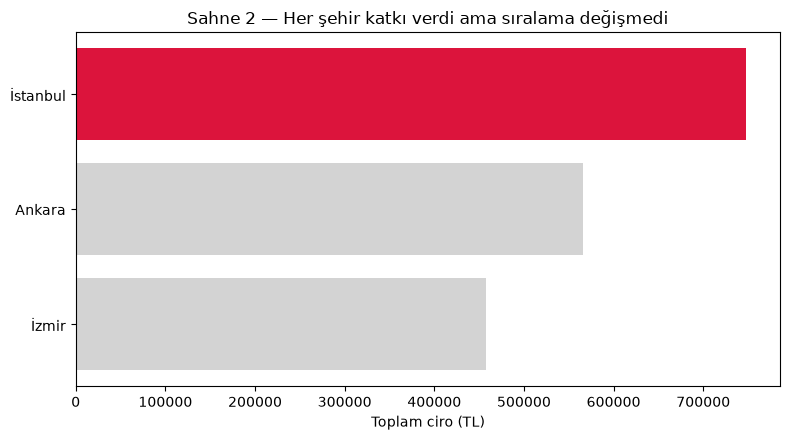

In [3]:
sirali = satis.groupby("sehir")["ciro"].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
renkler = ["lightgray", "lightgray", "crimson"]
ax.barh(sirali.index, sirali.values, color=renkler)
ax.set_title("Sahne 2 — Her şehir katkı verdi ama sıralama değişmedi")
ax.set_xlabel("Toplam ciro (TL)")
plt.tight_layout()
plt.show()

İkinci grafik hikâyenin yönünü belirler: kimse gerilemedi ama... Buraya kadar her şey alışıldık. Asıl merak uyandıran soru şudur: **büyümeyi kim hızlandırdı?** Üçüncü sahneye geçiyoruz.

### Sahne 3 — Bulgu: büyümenin motoru

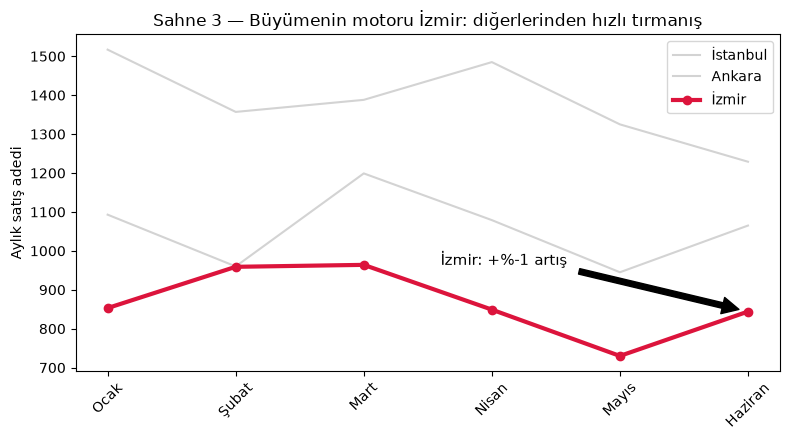

In [4]:
aylar_s = ["Ocak", "Şubat", "Mart", "Nisan", "Mayıs", "Haziran"]
ist = satis[satis["sehir"] == "İstanbul"].groupby("ay")["adet"].sum()
ank = satis[satis["sehir"] == "Ankara"].groupby("ay")["adet"].sum()
izm = satis[satis["sehir"] == "İzmir"].groupby("ay")["adet"].sum()

artis_orani = (izm.values[-1] / izm.values[0] - 1) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(6), ist.values, color="lightgray", linewidth=1.5, label="İstanbul")
ax.plot(range(6), ank.values, color="lightgray", linewidth=1.5, label="Ankara")
ax.plot(range(6), izm.values, color="crimson", linewidth=3, marker="o", label="İzmir")
ax.annotate(f"İzmir: +%{artis_orani:.0f} artış",
            xy=(5, izm.values[-1]), xytext=(2.6, izm.values[-1] + 120),
            arrowprops=dict(facecolor="black", shrink=0.05), fontsize=11)
ax.set_xticks(range(6), aylar_s, rotation=45)
ax.set_title("Sahne 3 — Büyümenin motoru İzmir: diğerlerinden hızlı tırmanış")
ax.set_ylabel("Aylık satış adedi")
ax.legend()
plt.tight_layout()
plt.show()

Üçüncü grafik, hikâyenin kalbidir: iki şehir sade gri (bağlam), İzmir kalın kırmızı (kahraman) ve `annotate` ile mesaj noktaya iliştirilmiş. 1. dersteki Grafik D'nin ilkeleri — vurgu, tek mesaj, sadeleştirme — rapor ölçeğinde uygulanıyor.

**Hikâyenin tamamı:** sahne 1 büyümeyi gösterdi, sahne 2 soruyu açtı, sahne 3 cevapladı. Sıradaki adım (gerçek hayatta) öneri grafiği ve eylem maddesidir: "İzmir modelini (ürün çeşitliliği mi, konum mu?) incele ve diğer şubelere uyarla."

### Başlık atölyesi

Aşağıdaki konu başlıklarını mesaj başlıklarına çevir. Her satır için cümleyi tamamlamayı dene; örnek çözümler "Cevaplar"da:

| Konu başlığı | Mesaj başlığı (? ) |
|---|---|
| Aylık satış adetleri | ... |
| Şehir bazında memnuniyet | ... |
| Öğrenci çalışma saatleri ve notlar | ... |
| Günlük vaka sayıları | ... |

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** Sahne 3'teki grafiği gri/kırmızı yerini değiştirerek çiz (İzmir gri, İstanbul kırmızı ve kalın). Başlığı da değiştirmeden bırak. Hikâye ne oldu? Başlık ile vurgu çelişince grafik ne hissettiriyor?

**Deney 2:** Sahne sıralamasını boz: önce Sahne 3'ü (bulguyu), sonra Sahne 1'i (bağlamı) göster. Bir arkadaşına iki versiyonu ayrı ayrı gösterip "ne anladın?" diye sor. Sıralamanın etkisini gözle.

**Deney 3:** Sahne 1'in başlığını "Ciro grafiği" yap ve y eksenini `ylim` ile sıkıştır (ör. `ax.set_ylim(aylik.values.min() - 1000, aylik.values.max() + 1000)`). Mesajsız başlık + sıkışık eksen birlikte ne gibi bir izlenim bırakıyor? (1. dersin "kesik eksen" uyarısıyla bağla.)

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| Sunum "grafik bombardımanı"na dönüyor | Her grafik ayrı hikâye anlatmaya çalışıyor | Hikâye cümlesini önce yaz; ona hizmet etmeyen grafiği çıkar |
| Başlıklar sıkıcı | Konu başlığı kullanılıyor | Her başlığa "bu grafik ne diyor?" sorusunun cevabını yaz |
| İzleyici "ve benim için ne var?" diyor | İzleyici tanımlanmamış | Sunum öncesi tek cümlelik izleyici profili yaz (kim, ne bilmiyor, neye karar verecek) |
| Hikâye veriyi abartıyor | Dürüstlük kontrolü atlandı | Her mesaj başlığını veriye geri doğrula; süsleyen kelime ve eksenleri temizle |
| Grafikler birbirine benzemiyor | Stil tutarlılığı yok | Renk dili, yazı boyutu ve konum tüm sahnelerde sabit olmalı |

> **İpucu:** Hikâyeyi test etmenin en hızlı yolu, grafikleri bir arkadaşına **başlıksız** göstermektir. Söylediği mesaj senin mesajınla uyuşuyorsa grafik kendi kendine anlatıyor demektir; uyuşmuyorsa vurgu ya da sıralamada iş var.

## 🏋️ Kendin Dene

Öğrenci verisi (`../Data/10-student-habits.csv`) için üç sahnelik bir hikâye kur:

1. **Hikâye cümlesini yaz:** "Öğrencilerin notunu en çok X belirliyor ve bu ilişki bölümden bağımsız" gibi (kendi bulgunu kullan).
2. **Üç grafiği üret:** bağlam (dağılım), soru (beklenti kırılması), bulgu (vurgulu grafik). Tutarlı stil ve mesaj başlıkları kullan.
3. **Anlatım testi:** Defteri bir arkadaşına aç (ya da ekran görüntülerini gönder) ve "üç grafikte ne anladın?" diye sor. Cevabı hikâye cümleyle karşılaştır; farkı not et.

<details>
<summary>İpucu</summary>

Bulgu adayı: çalışma saatinin notla korelasyonu 0.86 (10. ders); sosyal medyanın etkisi zayıf. "Beklenti kırılması" sahnesi olarak "kahve içen öğrenci notu yüksek görünüyor ama..." (ilişki ≠ neden) hikâyesi güçlüdür. Vurgu için 8. dersteki gri/kırmızı tekniğini kullan.

</details>

## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. Konu başlığı ile mesaj başlığı arasındaki farkı tanımla ve her birine örnek ver.
2. Klasik hikâye akışının dört adımını sırayla yaz.
3. Aynı analiz yöneticiye ve teknik ekibe nasıl farklı anlatılır? İki izleyicinin "ne istediğini" yaz.
4. "Hikâyenin kahramanı" ifadesi grafiklerde neye karşılık gelir? Hangi araçlarla kurulur?
5. Hikâyeleştirme dürüstlüğü bozabilir mi? İki örnek mekanizma say.
6. Grafiği başlıksız bir arkadaşına gösterme testi neyi ölçer?

## 🚀 Bağımsız Çalışma

- **Haber analizi:** Veri içeren bir haber yazısı bul (grafikli ekonomi ya da spor haberi). Hikâye cümlesini çıkar; grafiklerin bu cümleye hizmet edip etmediğini, başlıkların konu mu mesaj mı olduğunu değerlendir. Beş maddelik bir eleştiri yaz.
- **Kitap:** Cole Nussbaumer Knaflic — *Storytelling with Data* (1. derste önerdiğimiz kitap): bu dersin konusunun kitap uzunluğundaki hâli. İlk iki bölümü okumak bile bakışını değiştirir.

## 📚 Daha Fazlasını Öğrenmek

- Storytelling with Data blogu: https://www.storytellingwithdata.com/blog
- Matplotlib anotasyon rehberi: https://matplotlib.org/stable/tutorials/text/annotations.html

İngilizcedir; örnekler doğrudan incelenebilir.

## ✅ Kısa Özet

- Hikâye cümlesi grafikten önce gelir: ne söylüyorsan grafiğin onu taşıması için kurulur.
- Başlıklar mesaj taşır: "Aylık ciro" değil, "Altı ayda ciro %95 arttı".
- Akış: bağlam → soru → bulgu → öneri; en güçlü grafik kararı destekleyen yerde durur.
- Vurgu tutarlıdır: hikâyenin kahramanı tüm sahnelerde aynı renkte ve kalınlıkta.
- Dürüstlük anlatının sınırıdır: verinin söylemediğini hikâye de söylemez.
- Başlıksız izleyici testi, grafiğin kendi kendine anlatıp anlatmadığını ölçer.

Sıradaki ve son ders: tüm bu yetkinlikleri gerçek bir veri setine uygulayacağın mini proje.

---

[← Önceki ders: Üç Boyutlu Grafikler](14-Three-Dimensional-Plots.ipynb) · [Sıradaki ders: Mini Proje →](16-Mini-Project.ipynb)

## Cevaplar

<details>
<summary>Başlık atölyesi — örnek çözümler</summary>

- "Aylık satış adetleri" → "Satışlar yaz aylarında hızlandı"
- "Şehir bazında memnuniyet" → "Üç şehrin memnuniyeti birbirine yakın"
- "Öğrenci çalışma saatleri ve notlar" → "Haftada 5 saat üzeri çalışma notu belirgin biçimde yükseltiyor"
- "Günlük vaka sayıları" → "Nisan ortasından itibaren günlük artış yavaşladı"

(Kendi cümlelerin farklı olabilir; ölçüt: grafikteki örüntünün ne dediğini söylemek.)

</details>

<details>
<summary>Kontrol Et 1</summary>

Konu başlığı grafikte ne olduğunu söyler ("Aylık ciro"); mesaj başlığı örüntünün ne anlattığını söyler ("Ciro %95 arttı"). İlksi bir etiket, ikincisi bir cümledir.

</details>

<details>
<summary>Kontrol Et 2</summary>

Bağlam → soru/merak → bulgu → sonuç/öneri.

</details>

<details>
<summary>Kontrol Et 3</summary>

Yönetici karar ve etki ister: "hangi şubeye yatırım", "risk ne". Teknik ekip mekanizma ve neden ister: "artışın kaynağı hangi ürün/kanal". Aynı grafikler farklı vurgu ve sıralamayla iki hikâyeye dönüşür.

</details>

<details>
<summary>Kontrol Et 4</summary>

Hikâyenin kahramanı, vurgulanan veri öğesidir (bir seri, bir şehir, bir dönem). Renk (kahraman renkli, geri kalan gri), kalınlık/boyut, konum (en son grafik) ve `annotate` ile kurulur.

</details>

<details>
<summary>Kontrol Et 5</summary>

Evet. Örnekler: kesik ya da seçici eksenle oranı büyütmek; elverişli zaman aralığı ya da grup seçimi (cherry-picking); mesaj başlığında verinin taşımadığı bir nedensellik ima etmek.

</details>

<details>
<summary>Kontrol Et 6</summary>

Grafiğin vurgusunun ve sıralamasının, başlık desteği olmadan aynı mesajı taşıyıp taşıyamadığını. Uyuşuyorsa grafik kendi kendine anlatıyor; değilse başlık grafta olmayanı telafi etmeye çalışıyor demektir.

</details>